In [26]:
include("../src/population_model.jl")
include("../parameters/V2/RA_long.jl")

ComponentVector{Float64}(b0 = 1.0, g = 0.8976275964304349, m̄ = 0.11, m̲ = 0.8031471805599453, r0 = 0.02040344274221344, z = 0.75, b_target = 0.4, b_limit = 0.2, f_target = 0.08218551792854177, T = [0.975 0.5; 0.025 0.5], σ_R = 0.75, μZ = 0.0, μ_P = 51.49751867353916, μ_Ce = 4.0, s̄ = -2.0, ks = 0.025, kb = 0.08, δ = 0.93, y0 = 0.01, cf = 1.0e-6, cv = 0.0, κ_bankrupt = 0.01, γ = 1.001)

In [27]:
states, m, f, h, y = simulate_trajectory(p,500)

([-0.916290731874155 -0.8822084333463545 … -0.9533465694293436 -0.9532733934008281; 0.0 0.034082298527800536 … 0.020711935981976626 7.31760285155314e-5; 1.0 1.0 … 1.0 1.0], [0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11  …  0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11, 0.11], [0.08218551792854177, 0.08218551792854177, 0.08218551792854177, 0.08218551792854178, 0.08218551792854177, 0.08218551792854177, 0.08218551792854177, 0.08218551792854177, 0.08218551792854177, 0.08218551792854177  …  0.0070257966682825725, 0.01951721907892606, 0.027207449549451673, 0.03989068375991623, 0.057441527853618356, 0.06701139914266466, 0.06962275724226519, 0.07295922595013889, 0.07620608222289448, 0.07621767311522633], [0.03094515393422353, 0.03377977091080758, 0.034353968503552386, 0.034931351711594755, 0.03585219281252577, 0.03646221556161676, 0.0355604968952127, 0.03558181288223533, 0.03471643263381095, 0.03534660839980308  …  0.0014394155100209626, 0.004530691341402555, 0.00676796849

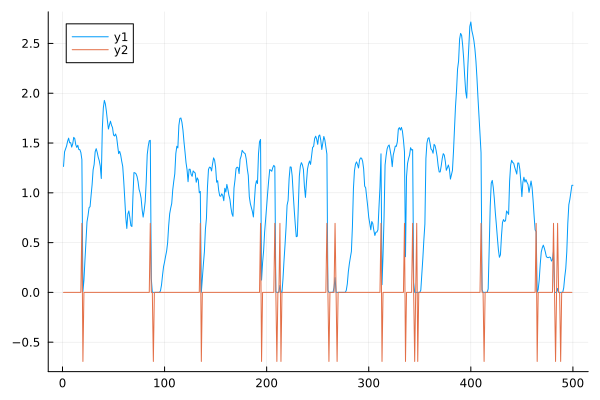

In [28]:
using Plots
Plots.plot(y)
Plots.plot!(m[2:end].-m[1:(end-1)])

In [29]:
"""
    average_revenue_shortfall(p; window=5, T=500)

Simulate a trajectory of length `T` from the population model with
parameters `p`, then compute the average revenue shortfall in the `window`
years following each switch of mortality `m` from low to high. Mean revenue
is calibrated to 1, so the shortfall for one event is
`window - sum(y over the window)` (positive = revenue below average). The
window starts in the first high-mortality year. Events whose window runs past
the end of the simulation are skipped. Returns `NaN` if there are no complete
events.
"""
function average_revenue_shortfall(p; window::Int=5, T::Int=5_000)
    states, m, f, h, y = simulate_trajectory(p, T)
    # indices t where m[t+1] > m[t], i.e. the first high-mortality year is t+1
    switches = findall(>(0), m[2:end] .- m[1:(end-1)]) .+ 1
    shortfalls = [window - sum(y[t:(t+window-1)])
                  for t in switches if t + window - 1 <= length(y)]
    return isempty(shortfalls) ? NaN : sum(shortfalls) / length(shortfalls)
end

average_revenue_shortfall(p; window=5, T=50_000)

4.29719175770713

In [30]:
"""
    average_running_mean_shortfall(p; window=5, T=500)

Like `average_revenue_shortfall`, but the benchmark is the trailing
`window`-year running mean of income (`y_5[t] = mean(y[t-window+1:t])`)
instead of the calibrated mean of 1. For each switch of mortality `m` from low
to high, the shortfall is `sum(y_5[t] - y[t])` over the `window` years starting
in the first high-mortality year (positive = income below its recent average).
Returns the mean across events. Events without a full running-mean history
before them, or whose window runs past the end of the simulation, are skipped.
Returns `NaN` if there are no complete events.
"""
function average_running_mean_shortfall(p; window::Int=5, T::Int=500)
    states, m, f, h, y = simulate_trajectory(p, T)
    # trailing running mean; y5[t] is defined for t >= window
    y5 = [sum(y[(t-window+1):t]) / window for t in window:length(y)]
    y5 = vcat(fill(NaN, window - 1), y5)
    switches = findall(>(0), m[2:end] .- m[1:(end-1)]) .+ 1
    shortfalls = [sum(y5[t:(t+window-1)] .- y[t:(t+window-1)])
                  for t in switches if t >= window && t + window - 1 <= length(y)]
    return isempty(shortfalls) ? NaN : sum(shortfalls) / length(shortfalls)
end

average_running_mean_shortfall(p; window=10, T=50_000)

2.4236196053803933